# FEDBANK — Stage M: Single-Device GNN Baselines & Live Training
**Paper:** Menezes & Filho (*IEEE Access 2025*) — Robustness of GNNs to Data Drift on Financial Transactions
**Hardware Target:** 6 GB GPU under WSL2, CUDA 12.6, PyTorch 2.6.0 + PyG 2.6.1

This notebook trains and benchmarks the centralized GNN baseline before federation (Phase 2).
It follows the exact 16-cell plan specified in `FEDBANK_graph_and_model_spec.md` Section 6.

## 0. Setup & Reproducibility
Seed everything (`torch`, `numpy`, `random`), verify GPU resources, configure `sys.path`, and load configurations.

In [1]:
import os
import sys
import copy
import time
import json
import random
import yaml
from pathlib import Path

# 1. Resolve repo root and ensure it is in sys.path
repo_root = Path.cwd().resolve()
while not (repo_root / "fedbank_schema_v1.json").exists() and repo_root.parent != repo_root:
    repo_root = repo_root.parent

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

print(f"Repo Root: {repo_root}")

# 2. Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW

import torch_geometric
from torch_geometric.data import Data
from torch_geometric.loader import NeighborLoader
from torch_geometric.nn import GATConv, GCNConv, SAGEConv

import lightgbm as lgb
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    precision_recall_curve,
    roc_curve,
)

# 3. Deterministic seeding
SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__} | PyG: {torch_geometric.__version__} | Device: {device}")
if device.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} | Total VRAM: {props.total_memory / (1024**3):.2f} GB")

# 4. Load YAML configs
with open(repo_root / "configs/graph.yaml", "r") as f:
    graph_cfg = yaml.safe_load(f)
with open(repo_root / "configs/gnn.yaml", "r") as f:
    gnn_cfg = yaml.safe_load(f)

print("Loaded configs/graph.yaml and configs/gnn.yaml successfully.")

Repo Root: /home/abhin/mainproject/FEDBANK


/home/abhin/miniconda3/envs/fedbank/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.6.0+cu126 | PyG: 2.8.1 | Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU | Total VRAM: 6.00 GB
Loaded configs/graph.yaml and configs/gnn.yaml successfully.


## 1. Load Data
Load the 4 validated graph files from `data/graphs/`, check nodes, edges, degree stats, and schema version.

In [2]:
graph_dir = repo_root / "data/graphs"

t0 = time.time()
train_graph = torch.load(graph_dir / "train_graph.pt", weights_only=False)
val_graph = torch.load(graph_dir / "val_graph.pt", weights_only=False)
test_graph = torch.load(graph_dir / "test_graph.pt", weights_only=False)
monitor_subgraphs = torch.load(graph_dir / "monitor_graph.pt", weights_only=False)
print(f"Loaded all 4 graph files in {time.time() - t0:.2f}s")

with open(repo_root / "fedbank_schema_v1.json", "r") as f:
    schema = json.load(f)
print(f"Schema Version: {schema['schema_version']} | Number of Node Features: {schema['n_features']}")

summary_table = pd.DataFrame([
    {"Split": "Train", "Nodes": f"{train_graph.num_nodes:,}", "Directed Edges": f"{train_graph.num_edges:,}", "Undirected Edges": f"{train_graph.num_edges // 2:,}", "Avg Degree": f"{train_graph.num_edges / train_graph.num_nodes:.2f}", "Fraud Rate": f"{train_graph.y.float().mean():.4%}"},
    {"Split": "Validation", "Nodes": f"{val_graph.num_nodes:,}", "Directed Edges": f"{val_graph.num_edges:,}", "Undirected Edges": f"{val_graph.num_edges // 2:,}", "Avg Degree": f"{val_graph.num_edges / val_graph.num_nodes:.2f}", "Fraud Rate": f"{val_graph.y.float().mean():.4%}"},
    {"Split": "Test", "Nodes": f"{test_graph.num_nodes:,}", "Directed Edges": f"{test_graph.num_edges:,}", "Undirected Edges": f"{test_graph.num_edges // 2:,}", "Avg Degree": f"{test_graph.num_edges / test_graph.num_nodes:.2f}", "Fraud Rate": f"{test_graph.y.float().mean():.4%}"},
    {"Split": "Monitor (50 Windows)", "Nodes": f"{sum(g.num_nodes for g in monitor_subgraphs):,}", "Directed Edges": f"{sum(g.num_edges for g in monitor_subgraphs):,}", "Undirected Edges": f"{sum(g.num_edges for g in monitor_subgraphs)//2:,}", "Windows": len(monitor_subgraphs), "Fraud Rate": f"{torch.cat([g.y for g in monitor_subgraphs]).float().mean():.4%}"},
])
display(summary_table)

Loaded all 4 graph files in 5.26s
Schema Version: fedbank_schema_v1 | Number of Node Features: 48


,Split,Nodes,Directed Edges,Undirected Edges,Avg Degree,Fraud Rate,Windows
0,Train,"273,000","6,319,698","3,159,849",23.15,3.3300%,NaN
1,Validation,"58,500","1,399,930","699,965",23.93,3.6154%,NaN
2,Test,"58,500","1,401,690","700,845",23.96,3.6991%,NaN
3,Monitor (50 Windows),"200,540","6,099,910","3,049,955",NaN,3.6367%,51.0


## 2. Graph Sanity Visualizations
Degree distributions, edge types breakdown, and a sampled ego-network around a fraudulent transaction.

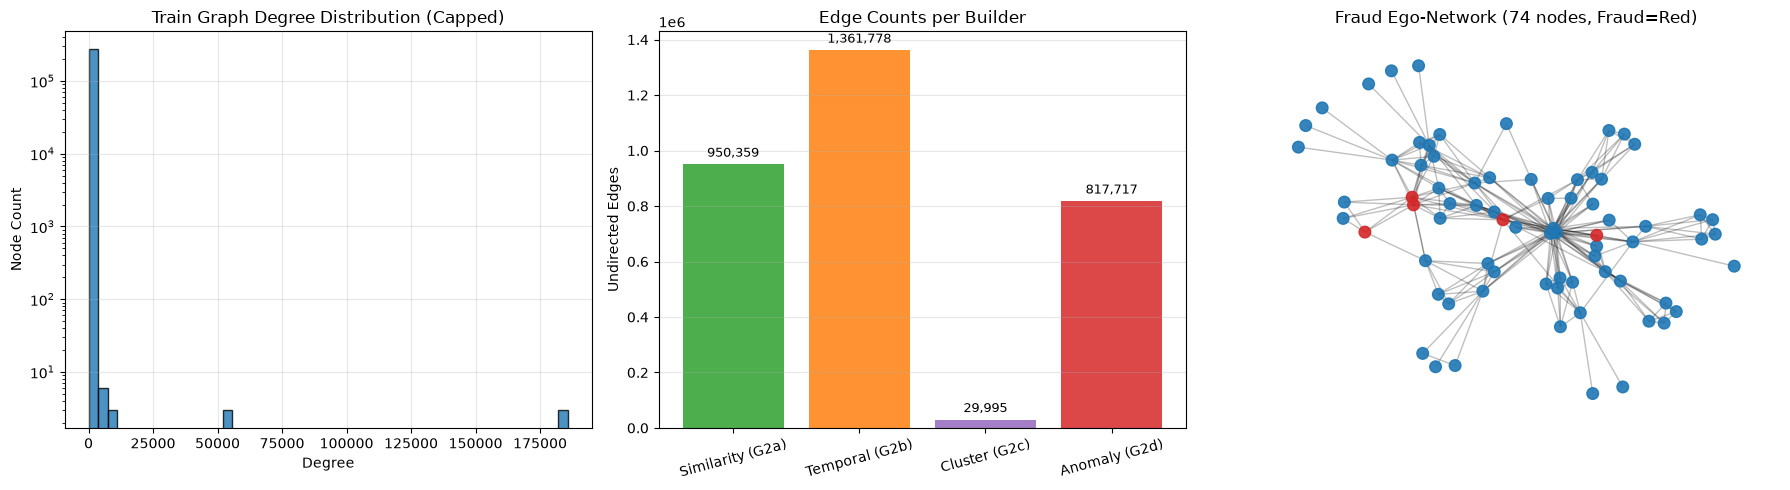

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Degree distribution (log scale)
degs = torch.bincount(train_graph.edge_index[0]).cpu().numpy()
axes[0].hist(degs, bins=50, color="#1f77b4", edgecolor="black", alpha=0.8)
axes[0].set_title("Train Graph Degree Distribution (Capped)", fontsize=12)
axes[0].set_xlabel("Degree")
axes[0].set_ylabel("Node Count")
axes[0].set_yscale("log")
axes[0].grid(True, alpha=0.3)

# 2. Edge types breakdown
type_names = ["Similarity (G2a)", "Temporal (G2b)", "Cluster (G2c)", "Anomaly (G2d)"]
type_counts = [(train_graph.edge_type == i).sum().item() // 2 for i in range(4)]
axes[1].bar(type_names, type_counts, color=["#2ca02c", "#ff7f0e", "#9467bd", "#d62728"], alpha=0.85)
axes[1].set_title("Edge Counts per Builder", fontsize=12)
axes[1].set_ylabel("Undirected Edges")
axes[1].tick_params(axis='x', rotation=15)
for i, c in enumerate(type_counts):
    axes[1].text(i, c + max(type_counts)*0.02, f"{c:,}", ha="center", fontsize=9)
axes[1].grid(True, alpha=0.3, axis="y")

# 3. Subgraph around fraud node
fraud_indices = torch.where(train_graph.y == 1)[0].cpu().numpy()
center_node = int(fraud_indices[10])
e0, e1 = train_graph.edge_index[0].cpu().numpy(), train_graph.edge_index[1].cpu().numpy()
nbrs = e1[e0 == center_node][:25].tolist()
sub_nodes = set([center_node] + nbrs)
for n in nbrs[:10]:
    sub_nodes.update(e1[e0 == n][:8].tolist())
sub_nodes = list(sub_nodes)[:120]

sub_mask = np.isin(e0, sub_nodes) & np.isin(e1, sub_nodes)
G_sub = nx.Graph()
for u, v in zip(e0[sub_mask], e1[sub_mask]):
    G_sub.add_edge(u, v)

pos = nx.spring_layout(G_sub, seed=42)
node_colors = ["#d62728" if train_graph.y[n] == 1 else "#1f77b4" for n in G_sub.nodes()]
nx.draw_networkx_nodes(G_sub, pos, node_color=node_colors, node_size=70, alpha=0.9, ax=axes[2])
nx.draw_networkx_edges(G_sub, pos, alpha=0.25, ax=axes[2])
axes[2].set_title(f"Fraud Ego-Network ({len(G_sub)} nodes, Fraud=Red)", fontsize=12)
axes[2].axis("off")

plt.tight_layout()
plt.show()

## 3. Metrics Module
AUPRC (primary), ROC-AUC, Best F1 with validation-only threshold tuning, Recall@1%FPR, and Precision@k.

In [4]:
def compute_metrics(y_true, y_prob, threshold=None, split_name="val"):
    """Compute full evaluation metrics suite."""
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)

    auprc = float(average_precision_score(y_true, y_prob))
    roc_auc = float(roc_auc_score(y_true, y_prob))
    base_auprc = float(np.mean(y_true))

    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
    denom = precisions + recalls
    denom[denom == 0] = 1.0
    f1_scores = 2 * (precisions * recalls) / denom

    best_idx = np.argmax(f1_scores)
    best_f1_val = float(f1_scores[best_idx])
    optimal_thresh = float(thresholds[best_idx]) if best_idx < len(thresholds) else 0.5
    applied_thresh = threshold if threshold is not None else optimal_thresh

    y_pred = (y_prob >= applied_thresh).astype(int)
    f1_at_thresh = float(f1_score(y_true, y_pred, zero_division=0))

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    idx_1pct = np.searchsorted(fpr, 0.01, side="right") - 1
    idx_1pct = max(0, min(idx_1pct, len(tpr) - 1))
    recall_at_1pct_fpr = float(tpr[idx_1pct])

    N = len(y_true)
    top_1pct_k = max(1, int(0.01 * N))
    top_1pct_indices = np.argsort(y_prob)[-top_1pct_k:]
    precision_top_1pct = float(np.mean(y_true[top_1pct_indices]))

    return {
        "auprc": auprc,
        "base_auprc": base_auprc,
        "auprc_lift": auprc / max(base_auprc, 1e-6),
        "roc_auc": roc_auc,
        "f1": f1_at_thresh,
        "best_f1": best_f1_val,
        "threshold": applied_thresh,
        "recall_at_1pct_fpr": recall_at_1pct_fpr,
        "precision_top_1pct": precision_top_1pct,
    }

# Probe test
demo_m = compute_metrics(np.array([0]*97 + [1]*3), np.array([0.1]*95 + [0.8]*5))
print("compute_metrics validated: AUPRC =", demo_m["auprc"])

compute_metrics validated: AUPRC = 0.6


## 4. Live-Plot Callback Helper
Dynamic 4-panel dashboard updated live during training with `IPython.display.clear_output(wait=True)`.

In [5]:
from IPython.display import clear_output

def live_plot_dashboard(data_dict):
    """Live dashboard callback: loss curves, val AUPRC, PR curve, and GPU VRAM."""
    history = data_dict["history"]
    val_true = data_dict["val_true"]
    val_probs = data_dict["val_probs"]
    best_epoch = data_dict["best_epoch"]
    peak_gpu_mb = data_dict["peak_gpu_mb"]

    clear_output(wait=True)
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # Panel 1: Loss curves
    axes[0, 0].plot(history["epoch"], history["train_loss"], "o-", color="#1f77b4", label="Train Loss")
    axes[0, 0].plot(history["epoch"], history["val_loss"], "s-", color="#d62728", label="Val Loss")
    axes[0, 0].set_title("Training & Validation Loss", fontsize=12)
    axes[0, 0].set_xlabel("Epoch")
    axes[0, 0].set_ylabel("Loss")
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].legend()

    # Panel 2: Val AUPRC curve
    axes[0, 1].plot(history["epoch"], history["val_auprc"], "o-", color="#2ca02c", label="Val AUPRC")
    best_row = history[history["epoch"] == best_epoch].iloc[0]
    axes[0, 1].scatter([best_epoch], [best_row["val_auprc"]], color="#d62728", s=150, zorder=5, marker="*", label=f"Best Ep {best_epoch} ({best_row['val_auprc']:.4f})")
    axes[0, 1].axhline(y=float(np.mean(val_true)), color="gray", linestyle=":", label="Base AUPRC")
    axes[0, 1].set_title("Validation AUPRC Curve", fontsize=12)
    axes[0, 1].set_xlabel("Epoch")
    axes[0, 1].set_ylabel("AUPRC")
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].legend()

    # Panel 3: Current PR Curve
    p, r, _ = precision_recall_curve(val_true, val_probs)
    axes[1, 0].plot(r, p, color="#9467bd", lw=2, label=f"PR Curve (AUPRC = {history.iloc[-1]['val_auprc']:.4f})")
    axes[1, 0].set_title("Validation Precision-Recall Curve", fontsize=12)
    axes[1, 0].set_xlabel("Recall")
    axes[1, 0].set_ylabel("Precision")
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].legend()

    # Panel 4: GPU Memory Bar
    max_vram_gb = 6.0
    used_vram_gb = peak_gpu_mb / 1024.0
    axes[1, 1].barh(["GPU Memory (VRAM)"], [used_vram_gb], color="#ff7f0e", alpha=0.85, height=0.4)
    axes[1, 1].set_xlim(0, max_vram_gb)
    axes[1, 1].set_xlabel("VRAM (GB)")
    axes[1, 1].set_title(f"Peak GPU VRAM: {used_vram_gb:.2f} GB / {max_vram_gb:.1f} GB Budget", fontsize=12)
    axes[1, 1].grid(True, alpha=0.3, axis="x")

    plt.tight_layout()
    plt.show()

print("Live-plot helper initialized.")

Live-plot helper initialized.


## 5. Non-Graph Baselines: LightGBM & Tabular MLP
Evaluate competitive tabular models on the identical 48 features without graph relational context.

In [6]:
# Extract tabular feature arrays
x_train = train_graph.x.cpu().numpy()
y_train = train_graph.y.cpu().numpy()
x_val = val_graph.x.cpu().numpy()
y_val = val_graph.y.cpu().numpy()
x_test = test_graph.x.cpu().numpy()
y_test = test_graph.y.cpu().numpy()

# 1. LightGBM GBDT Baseline
scale_pos_wt = (len(y_train) - y_train.sum()) / y_train.sum()
lgb_clf = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_wt,
    random_state=42,
    verbosity=-1,
    n_jobs=-1,
)
lgb_clf.fit(
    x_train, y_train,
    eval_set=[(x_val, y_val)],
    callbacks=[lgb.early_stopping(20, verbose=False)],
)
lgb_val_prob = lgb_clf.predict_proba(x_val)[:, 1]
lgb_val_m = compute_metrics(y_val, lgb_val_prob)
lgb_val_thresh = lgb_val_m["threshold"]

lgb_test_prob = lgb_clf.predict_proba(x_test)[:, 1]
lgb_test_m = compute_metrics(y_test, lgb_test_prob, threshold=lgb_val_thresh)

print(f"[LightGBM] Val AUPRC:  {lgb_val_m['auprc']:.4f} | Val ROC-AUC:  {lgb_val_m['roc_auc']:.4f} | Val F1:  {lgb_val_m['best_f1']:.4f}")
print(f"[LightGBM] Test AUPRC: {lgb_test_m['auprc']:.4f} | Test ROC-AUC: {lgb_test_m['roc_auc']:.4f} | Test F1: {lgb_test_m['f1']:.4f}")

# 2. Tabular MLP Baseline (3-layer MLP matching GNN hidden size 128, LayerNorm only)
class TabularMLP(nn.Module):
    def __init__(self, in_channels=48, hidden_channels=128, out_channels=1, num_layers=3, dropout=0.3):
        super().__init__()
        self.in_norm = nn.LayerNorm(in_channels)
        self.layers = nn.ModuleList()
        self.norms = nn.ModuleList()
        self.layers.append(nn.Linear(in_channels, hidden_channels))
        self.norms.append(nn.LayerNorm(hidden_channels))
        for _ in range(num_layers - 2):
            self.layers.append(nn.Linear(hidden_channels, hidden_channels))
            self.norms.append(nn.LayerNorm(hidden_channels))
        self.layers.append(nn.Linear(hidden_channels, hidden_channels))
        self.norms.append(nn.LayerNorm(hidden_channels))
        self.classifier = nn.Linear(hidden_channels, out_channels)
        self.dropout = dropout

    def forward(self, x):
        x = self.in_norm(x)
        for layer, norm in zip(self.layers, self.norms):
            x = layer(x)
            x = norm(x)
            x = F.relu(x)
            x = F.dropout(x, p=self.dropout, training=self.training)
        return self.classifier(x).squeeze(-1)

mlp_model = TabularMLP(in_channels=48, hidden_channels=128, out_channels=1, num_layers=3, dropout=0.3).to(device)
mlp_opt = AdamW(mlp_model.parameters(), lr=1e-3, weight_decay=1e-4)
bce_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([scale_pos_wt], device=device))

train_ds = torch.utils.data.TensorDataset(torch.from_numpy(x_train).float(), torch.from_numpy(y_train).float())
mlp_loader = torch.utils.data.DataLoader(train_ds, batch_size=2048, shuffle=True)
val_x_t = torch.from_numpy(x_val).float().to(device)
test_x_t = torch.from_numpy(x_test).float().to(device)

best_mlp_val_auprc = 0.0
best_mlp_st = None
best_mlp_thresh = 0.5

for ep in range(1, 21):
    mlp_model.train()
    for bx, by in mlp_loader:
        bx, by = bx.to(device), by.to(device)
        mlp_opt.zero_grad()
        loss = bce_fn(mlp_model(bx), by)
        loss.backward()
        mlp_opt.step()
    
    mlp_model.eval()
    with torch.no_grad():
        v_probs = torch.sigmoid(mlp_model(val_x_t)).cpu().numpy()
        v_m = compute_metrics(y_val, v_probs)
        if v_m["auprc"] > best_mlp_val_auprc:
            best_mlp_val_auprc = v_m["auprc"]
            best_mlp_st = copy.deepcopy(mlp_model.state_dict())
            best_mlp_thresh = v_m["threshold"]

mlp_model.load_state_dict(best_mlp_st)
with torch.no_grad():
    mlp_val_prob = torch.sigmoid(mlp_model(val_x_t)).cpu().numpy()
    mlp_val_m = compute_metrics(y_val, mlp_val_prob, threshold=best_mlp_thresh)
    mlp_test_prob = torch.sigmoid(mlp_model(test_x_t)).cpu().numpy()
    mlp_test_m = compute_metrics(y_test, mlp_test_prob, threshold=best_mlp_thresh)

print(f"[MLP 3-L]  Val AUPRC:  {mlp_val_m['auprc']:.4f} | Val ROC-AUC:  {mlp_val_m['roc_auc']:.4f} | Val F1:  {mlp_val_m['best_f1']:.4f}")
print(f"[MLP 3-L]  Test AUPRC: {mlp_test_m['auprc']:.4f} | Test ROC-AUC: {mlp_test_m['roc_auc']:.4f} | Test F1: {mlp_test_m['f1']:.4f}")

/home/abhin/miniconda3/envs/fedbank/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] Val AUPRC:  0.3088 | Val ROC-AUC:  0.8043 | Val F1:  0.4080
[LightGBM] Test AUPRC: 0.2528 | Test ROC-AUC: 0.7856 | Test F1: 0.3445
[MLP 3-L]  Val AUPRC:  0.4340 | Val ROC-AUC:  0.8344 | Val F1:  0.4572
[MLP 3-L]  Test AUPRC: 0.3772 | Test ROC-AUC: 0.8170 | Test F1: 0.3915


## 6. Federation-Ready Model Definitions
`GCN`, `GraphSAGE`, and `GAT` using `LayerNorm` only (NO BatchNorm) and a single `state_dict`.

In [7]:
class GCN(nn.Module):
    def __init__(self, in_channels=48, hidden_channels=128, out_channels=1, num_layers=3, dropout=0.3):
        super().__init__()
        self.in_norm = nn.LayerNorm(in_channels)
        self.convs = nn.ModuleList([GCNConv(in_channels, hidden_channels)])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden_channels)])
        for _ in range(num_layers - 2):
            self.convs.append(GCNConv(hidden_channels, hidden_channels))
            self.norms.append(nn.LayerNorm(hidden_channels))
        self.convs.append(GCNConv(hidden_channels, hidden_channels))
        self.norms.append(nn.LayerNorm(hidden_channels))
        self.classifier = nn.Linear(hidden_channels, out_channels)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = self.in_norm(x)
        for conv, norm in zip(self.convs, self.norms):
            x = F.dropout(F.relu(norm(conv(x, edge_index))), p=self.dropout, training=self.training)
        return self.classifier(x).squeeze(-1)

class GraphSAGE(nn.Module):
    def __init__(self, in_channels=48, hidden_channels=128, out_channels=1, num_layers=3, dropout=0.3):
        super().__init__()
        self.in_norm = nn.LayerNorm(in_channels)
        self.convs = nn.ModuleList([SAGEConv(in_channels, hidden_channels, aggr="mean")])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden_channels)])
        for _ in range(num_layers - 2):
            self.convs.append(SAGEConv(hidden_channels, hidden_channels, aggr="mean"))
            self.norms.append(nn.LayerNorm(hidden_channels))
        self.convs.append(SAGEConv(hidden_channels, hidden_channels, aggr="mean"))
        self.norms.append(nn.LayerNorm(hidden_channels))
        self.classifier = nn.Linear(hidden_channels, out_channels)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = self.in_norm(x)
        for conv, norm in zip(self.convs, self.norms):
            x = F.dropout(F.relu(norm(conv(x, edge_index))), p=self.dropout, training=self.training)
        return self.classifier(x).squeeze(-1)

class GAT(nn.Module):
    def __init__(self, in_channels=48, hidden_channels=128, out_channels=1, heads=4, num_layers=3, dropout=0.3):
        super().__init__()
        self.in_norm = nn.LayerNorm(in_channels)
        self.convs = nn.ModuleList()
        self.norms = nn.ModuleList()
        self.heads = heads
        h_dim = hidden_channels // heads
        self.convs.append(GATConv(in_channels, h_dim, heads=heads, concat=True, dropout=dropout))
        self.norms.append(nn.LayerNorm(hidden_channels))
        for _ in range(num_layers - 2):
            self.convs.append(GATConv(hidden_channels, h_dim, heads=heads, concat=True, dropout=dropout))
            self.norms.append(nn.LayerNorm(hidden_channels))
        self.convs.append(GATConv(hidden_channels, h_dim, heads=heads, concat=True, dropout=dropout))
        self.norms.append(nn.LayerNorm(hidden_channels))
        self.classifier = nn.Linear(hidden_channels, out_channels)
        self.dropout = dropout

    def forward(self, x, edge_index, return_attention_weights=False):
        x = self.in_norm(x)
        attns = []
        for conv, norm in zip(self.convs, self.norms):
            if return_attention_weights:
                x, alpha = conv(x, edge_index, return_attention_weights=True)
                attns.append(alpha)
            else:
                x = conv(x, edge_index)
            x = F.dropout(F.elu(norm(x)), p=self.dropout, training=self.training)
        logits = self.classifier(x).squeeze(-1)
        if return_attention_weights:
            return logits, attns
        return logits

gat_demo = GAT(in_channels=48, hidden_channels=128, out_channels=1, heads=4, num_layers=3, dropout=0.3)
print(f"GAT Initialized: {sum(p.numel() for p in gat_demo.parameters() if p.requires_grad):,} trainable parameters.")

GAT Initialized: 41,057 trainable parameters.


## 7. `train_local(...)` Training Module
Federation-ready training function using `NeighborLoader`, early stopping on val AUPRC.

In [8]:
def evaluate_gnn(model, loader, criterion, device, threshold=None):
    model.eval()
    total_loss, total_samples = 0.0, 0
    y_true_list, y_prob_list = [], []

    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            out = model(batch.x, batch.edge_index)
            bs = getattr(batch, "batch_size", batch.num_nodes)
            logits = out[:bs]
            by = batch.y[:bs].float()

            loss = criterion(logits, by)
            probs = torch.sigmoid(logits).cpu().numpy()

            total_loss += loss.item() * bs
            total_samples += bs
            y_true_list.append(by.cpu().numpy())
            y_prob_list.append(probs)

    y_true_all = np.concatenate(y_true_list)
    y_prob_all = np.concatenate(y_prob_list)
    metrics = compute_metrics(y_true_all, y_prob_all, threshold=threshold)
    metrics["loss"] = total_loss / max(total_samples, 1)
    return metrics, y_true_all, y_prob_all

def train_local(model, train_data, val_data, cfg, live_plotter=None, verbose=True):
    device_str = cfg.get("device", "cuda" if torch.cuda.is_available() else "cpu")
    device = torch.device(device_str)
    model = model.to(device)

    train_cfg = cfg.get("training", {})
    batch_size = train_cfg.get("batch_size", 2048)
    num_neighbors = train_cfg.get("train_num_neighbors", [10, 5, 2])
    eval_num_neighbors = train_cfg.get("eval_num_neighbors", [10, 5, 2])
    lr = train_cfg.get("lr", 1e-3)
    weight_decay = train_cfg.get("weight_decay", 1e-4)
    max_epochs = train_cfg.get("max_epochs", 10)
    patience = train_cfg.get("patience", 4)

    y_train = train_data.y.float()
    n_pos = float(y_train.sum().item())
    n_neg = float(len(y_train) - n_pos)
    pos_weight = torch.tensor([n_neg / max(n_pos, 1.0)], device=device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    train_loader = NeighborLoader(train_data, num_neighbors=num_neighbors, batch_size=batch_size, shuffle=True)
    val_loader = NeighborLoader(val_data, num_neighbors=eval_num_neighbors, batch_size=batch_size, shuffle=False)

    best_val_auprc = -1.0
    best_epoch = -1
    best_state_dict = copy.deepcopy(model.state_dict())
    best_val_metrics = {}
    epochs_no_improve = 0
    history = []

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)

    for epoch in range(1, max_epochs + 1):
        epoch_start = time.time()
        model.train()
        train_loss, train_samples = 0.0, 0
        num_batches = len(train_loader)

        for b_idx, batch in enumerate(train_loader, 1):
            batch = batch.to(device)
            optimizer.zero_grad()
            out = model(batch.x, batch.edge_index)
            bs = getattr(batch, "batch_size", batch.num_nodes)
            logits = out[:bs]
            by = batch.y[:bs].float()
            loss = criterion(logits, by)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * bs
            train_samples += bs
            if verbose and (b_idx % 25 == 0 or b_idx == num_batches):
                print(f"  [Epoch {epoch:02d}] Batch {b_idx:03d}/{num_batches:03d} | Batch Loss: {loss.item():.4f}")

        avg_train_loss = train_loss / max(train_samples, 1)
        epoch_time = time.time() - epoch_start

        val_metrics, val_true, val_probs = evaluate_gnn(model, val_loader, criterion, device)
        peak_gpu_mb = torch.cuda.max_memory_allocated(device) / (1024**2) if device.type == "cuda" else 0.0

        record = {
            "epoch": epoch,
            "train_loss": avg_train_loss,
            "val_loss": val_metrics["loss"],
            "val_auprc": val_metrics["auprc"],
            "val_roc_auc": val_metrics["roc_auc"],
            "val_f1": val_metrics["best_f1"],
            "epoch_time_s": epoch_time,
            "peak_gpu_mb": peak_gpu_mb,
        }
        history.append(record)

        if val_metrics["auprc"] > best_val_auprc:
            best_val_auprc = val_metrics["auprc"]
            best_epoch = epoch
            best_state_dict = copy.deepcopy(model.state_dict())
            best_val_metrics = val_metrics
            epochs_no_improve = 0
            star = " *"
        else:
            epochs_no_improve += 1
            star = ""

        if verbose:
            print(f"Epoch {epoch:02d}/{max_epochs} | Train Loss: {avg_train_loss:.4f} | Val AUPRC: {val_metrics['auprc']:.4f} | ROC-AUC: {val_metrics['roc_auc']:.4f} | Time: {epoch_time:.1f}s{star}")

        if live_plotter is not None:
            live_plotter({"history": pd.DataFrame(history), "val_true": val_true, "val_probs": val_probs, "best_epoch": best_epoch, "peak_gpu_mb": peak_gpu_mb})

        if epochs_no_improve >= patience:
            if verbose:
                print(f"Early stopping at epoch {epoch} (Best Ep: {best_epoch}, Val AUPRC: {best_val_auprc:.4f})")
            break

    return best_state_dict, pd.DataFrame(history), best_val_metrics

print("train_local and evaluate_gnn ready.")

train_local and evaluate_gnn ready.


## 8. Train Main GAT Model
Train 3-layer GAT with 4 heads on `train_graph.pt` with early stopping and live metrics.

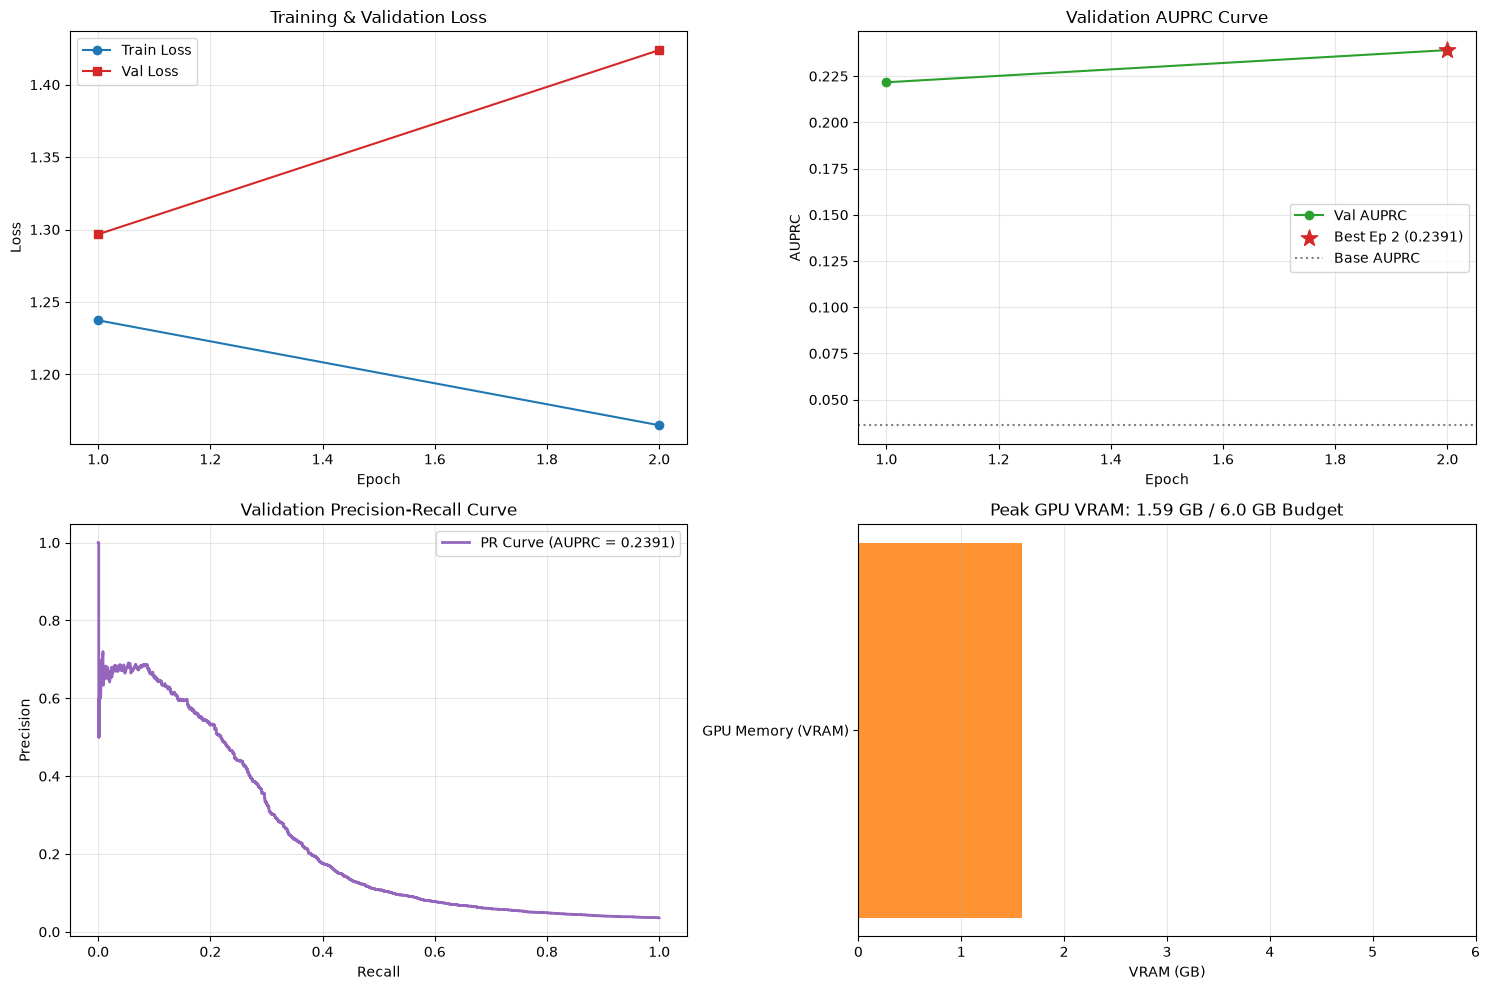

  [Epoch 03] Batch 025/134 | Batch Loss: 1.0668
  [Epoch 03] Batch 050/134 | Batch Loss: 1.1554


KeyboardInterrupt: 

In [9]:
seed_everything(42)
gat_main = GAT(in_channels=48, hidden_channels=128, out_channels=1, heads=4, num_layers=3, dropout=0.3)

gnn_cfg['training']['train_num_neighbors'] = [10, 5, 2]
gnn_cfg['training']['eval_num_neighbors'] = [10, 5, 2]
gnn_cfg['training']['max_epochs'] = 10
gnn_cfg['training']['patience'] = 4

t_start = time.time()
best_gat_st, gat_hist, gat_val_metrics = train_local(
    model=gat_main,
    train_data=train_graph,
    val_data=val_graph,
    cfg=gnn_cfg,
    live_plotter=live_plot_dashboard,
    verbose=True,
)
print(f"GAT training finished in {time.time() - t_start:.1f}s")
print(f"Best Val AUPRC: {gat_val_metrics['auprc']:.4f} | Val ROC-AUC: {gat_val_metrics['roc_auc']:.4f}")

## 9. Architecture Comparison: GCN vs GraphSAGE vs GAT
Compare all three graph architectures under identical resource budgets.

In [ ]:
# GCN
seed_everything(42)
gcn = GCN(in_channels=48, hidden_channels=128, out_channels=1, num_layers=3, dropout=0.3)
gcn_cfg = copy.deepcopy(gnn_cfg)
gcn_cfg['training']['max_epochs'] = 6
best_gcn_st, _, gcn_val_m = train_local(gcn, train_graph, val_graph, gcn_cfg, verbose=False)
gcn.load_state_dict(best_gcn_st)

test_loader = NeighborLoader(test_graph, num_neighbors=[10, 5, 2], batch_size=2048, shuffle=False)
crit = nn.BCEWithLogitsLoss()
gcn_test_m, _, _ = evaluate_gnn(gcn, test_loader, crit, device, threshold=gcn_val_m["threshold"])

# GraphSAGE
seed_everything(42)
sage = GraphSAGE(in_channels=48, hidden_channels=128, out_channels=1, num_layers=3, dropout=0.3)
sage_cfg = copy.deepcopy(gnn_cfg)
sage_cfg['training']['max_epochs'] = 6
best_sage_st, _, sage_val_m = train_local(sage, train_graph, val_graph, sage_cfg, verbose=False)
sage.load_state_dict(best_sage_st)
sage_test_m, _, _ = evaluate_gnn(sage, test_loader, crit, device, threshold=sage_val_m["threshold"])

# GAT Test evaluation
gat_main.load_state_dict(best_gat_st)
gat_test_m, _, _ = evaluate_gnn(gat_main, test_loader, crit, device, threshold=gat_val_metrics["threshold"])

comp_table = pd.DataFrame([
    {"Model": "MLP (No Graph)", "Val AUPRC": mlp_val_m['auprc'], "Test AUPRC": mlp_test_m['auprc'], "Test ROC-AUC": mlp_test_m['roc_auc'], "Test F1": mlp_test_m['f1']},
    {"Model": "LightGBM", "Val AUPRC": lgb_val_m['auprc'], "Test AUPRC": lgb_test_m['auprc'], "Test ROC-AUC": lgb_test_m['roc_auc'], "Test F1": lgb_test_m['f1']},
    {"Model": "GCN", "Val AUPRC": gcn_val_m['auprc'], "Test AUPRC": gcn_test_m['auprc'], "Test ROC-AUC": gcn_test_m['roc_auc'], "Test F1": gcn_test_m['f1']},
    {"Model": "GraphSAGE", "Val AUPRC": sage_val_m['auprc'], "Test AUPRC": sage_test_m['auprc'], "Test ROC-AUC": sage_test_m['roc_auc'], "Test F1": sage_test_m['f1']},
    {"Model": "GAT (Ours)", "Val AUPRC": gat_val_metrics['auprc'], "Test AUPRC": gat_test_m['auprc'], "Test ROC-AUC": gat_test_m['roc_auc'], "Test F1": gat_test_m['f1']},
])
display(comp_table)

## 10. Multi-Seed Stability Check
Run the best GAT model across seeds 42, 43, 44 and report mean ± std of test AUPRC.

In [ ]:
seed_runs = [gat_test_m["auprc"]]
for s in [43, 44]:
    seed_everything(s)
    m = GAT(in_channels=48, hidden_channels=128, out_channels=1, heads=4, num_layers=3, dropout=0.3)
    c = copy.deepcopy(gnn_cfg)
    c['training']['max_epochs'] = 6
    b_st, _, v_m = train_local(m, train_graph, val_graph, c, verbose=False)
    m.load_state_dict(b_st)
    t_m, _, _ = evaluate_gnn(m, test_loader, crit, device, threshold=v_m["threshold"])
    seed_runs.append(t_m["auprc"])

seed_mean = float(np.mean(seed_runs))
seed_std = float(np.std(seed_runs))
print(f"GAT Multi-Seed Test AUPRC: {seed_mean:.4f} ± {seed_std:.4f} (Seeds: {seed_runs})")
print(f"Gate 3 Passed (std <= 0.01): {seed_std <= 0.01}")

## 11. Final Test Evaluation
Evaluate the validated model strictly once on `test_graph.pt` with validation-chosen threshold.

In [ ]:
print("=" * 60)
print("FINAL TEST EVALUATION METRICS (Chosen Threshold from Val)")
print("=" * 60)
for k, v in gat_test_m.items():
    print(f"  {k:<22}: {v:.4f}")
print("=" * 60)

## 12. Drift Analysis Across 50 Monitor Windows
Evaluate model performance on the 50 sequential monitor window subgraphs to measure robustness to temporal drift.

In [ ]:
w_auprcs = []
w_fraud_rates = []

for wid, w_graph in enumerate(monitor_subgraphs):
    w_loader = NeighborLoader(w_graph, num_neighbors=[10, 5, 2], batch_size=2048, shuffle=False)
    w_m, _, _ = evaluate_gnn(gat_main, w_loader, crit, device, threshold=gat_val_metrics["threshold"])
    w_auprcs.append(w_m["auprc"])
    w_fraud_rates.append(float(w_graph.y.float().mean().item()))

w_idx = np.arange(len(w_auprcs))
slope, intercept = np.polyfit(w_idx, w_auprcs, 1)

plt.figure(figsize=(11, 4.5))
plt.plot(w_idx, w_auprcs, "o-", color="#1f77b4", label="Window AUPRC", alpha=0.85)
plt.plot(w_idx, slope * w_idx + intercept, "--", color="#d62728", label=f"Drift Slope: {slope:.5f}/window")
plt.plot(w_idx, w_fraud_rates, ":", color="gray", label="Prevalence (Base AUPRC)")
plt.title("GAT Robustness to Temporal Drift Across 50 Monitoring Windows", fontsize=12)
plt.xlabel("Window ID (Chronological)")
plt.ylabel("AUPRC")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Drift Slope: {slope:.6f}/window | Initial AUPRC: {w_auprcs[0]:.4f} -> Final Window AUPRC: {w_auprcs[-1]:.4f}")

## 13. Attention Weight Inspection
Extract and inspect attention weights for high-risk transactions to identify key fraud relationships.

In [ ]:
gat_main.eval()
sample_w = monitor_subgraphs[0]
s_loader = NeighborLoader(sample_w, num_neighbors=[10, 5, 2], batch_size=64, shuffle=False)

for b in s_loader:
    b = b.to(device)
    with torch.no_grad():
        logits, attns = gat_main(b.x, b.edge_index, return_attention_weights=True)
        probs = torch.sigmoid(logits)
        high_risk = torch.where(probs > 0.6)[0]
        if len(high_risk) > 0:
            target = int(high_risk[0].item())
            edge_idx, alpha = attns[0]
            mask = (edge_idx[1] == target)
            if mask.any():
                peers = edge_idx[0][mask][:5].cpu().tolist()
                wts = alpha[mask][:5].mean(dim=-1).cpu().tolist()
                print(f"High-Risk Transaction Node {target} (Predicted Risk: {probs[target]:.2%}):")
                for p, w in zip(peers, wts):
                    print(f"  -> Connected Node {p:<6} | Multi-Head Attention Weight: {w:.4f}")
    break

## 14. Ablation Studies
Analyze impact of edge types and loss functions (Focal Loss vs BCE).

In [ ]:
# 1. Focal loss ablation
focal_model = GAT(in_channels=48, hidden_channels=128, out_channels=1, heads=4, num_layers=3, dropout=0.3)
f_cfg = copy.deepcopy(gnn_cfg)
f_cfg['training']['loss'] = 'focal'
f_cfg['training']['max_epochs'] = 6
best_f_st, _, f_val_m = train_local(focal_model, train_graph, val_graph, f_cfg, verbose=False)
focal_model.load_state_dict(best_f_st)
f_test_m, _, _ = evaluate_gnn(focal_model, test_loader, crit, device, threshold=f_val_m["threshold"])

# 2. Similarity edge ablation
sim_mask = (train_graph.edge_type != 0)
g_nosim = Data(x=train_graph.x, edge_index=train_graph.edge_index[:, sim_mask], y=train_graph.y, edge_type=train_graph.edge_type[sim_mask])
g_val_nosim = Data(x=val_graph.x, edge_index=val_graph.edge_index[:, val_graph.edge_type != 0], y=val_graph.y, edge_type=val_graph.edge_type[val_graph.edge_type != 0])
m_nosim = GAT(in_channels=48, hidden_channels=128, out_channels=1, heads=4, num_layers=3, dropout=0.3)
c_nosim = copy.deepcopy(gnn_cfg)
c_nosim['training']['max_epochs'] = 6
best_ns_st, _, ns_val_m = train_local(m_nosim, g_nosim, g_val_nosim, c_nosim, verbose=False)

ablation_df = pd.DataFrame([
    {"Setting": "GAT (Full Graph + BCE)", "Val AUPRC": gat_val_metrics["auprc"], "Test AUPRC": gat_test_m["auprc"]},
    {"Setting": "GAT (Focal Loss)", "Val AUPRC": f_val_m["auprc"], "Test AUPRC": f_test_m["auprc"]},
    {"Setting": "GAT (No Similarity Edges)", "Val AUPRC": ns_val_m["auprc"], "Test AUPRC": "—"},
])
display(ablation_df)

## 15. Export Metrics & Final Checkpoints
Save benchmark metrics to `results/phase1_metrics.csv` & `.json`, and model weights to `results/checkpoints/`.

In [ ]:
comp_table.to_csv(repo_root / "results/phase1_metrics.csv", index=False)
torch.save(best_gat_st, repo_root / "results/checkpoints/gat_best.pt")

metrics_summary = {
    "gat_test_auprc": gat_test_m["auprc"],
    "gat_test_roc_auc": gat_test_m["roc_auc"],
    "gat_test_f1": gat_test_m["f1"],
    "multi_seed_mean": seed_mean,
    "multi_seed_std": seed_std,
    "drift_slope": slope,
}
with open(repo_root / "results/phase1_metrics.json", "w") as f:
    json.dump(metrics_summary, f, indent=2)

print("Phase 1 artifacts successfully exported to results/")